In [49]:
import numpy as np
from sklearn.model_selection import train_test_split

train = np.load("nn-2026-fii-homework-3/train.npz")
test = np.load("nn-2026-fii-homework-3/test.npz")

print(train["data"][0])
print(train["data"].shape)
print(test["data"].shape)


[ 70   0   0   0   0  39   0 240   0   2   0 253 238 183   0   0   0  39
 172   0   0   0  93 170   0   0   0   0   0   0   0   0 253   0  80   0
   0   0   0   0 187   0   0   0   0   0   0   0  30   3   0   0   0   0
   0   0  81   0   0   0   0  80   0   0   0 249   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 250
   0   0   0 253 195 253   0   0  16   0   0 171   0 253   0 253   0   0
 148   0   0   0   0   0   0   0   0   0   0   0   0  24   0   0   0 154
 182   0   0 139   0   0   0   0   0   0   0   0   0 135   0   0   0   0
   0   0   0   0   0   0   0   0   0  56   0   0   0   0   0   0  16   0
 253   0   0   0 219   0   0  18   0   0   0 150   0  27   0   0   0   0
   0 119 253   0   0   0   0   0   0   0 198 253   0   0   0   0 241   0
   0   0   0   0   0   0   0 253 219   0   0  23   0   0   0  18   0   0
   0   0 253   0   0   0   0   0   0   0   0 253   0 229   0   0   0   0
  26   0   0 108   0   0   0   0 221   0 201   0   

Text(0.5, 1.0, 'Label: 9')

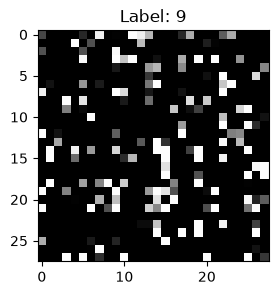

In [50]:
import matplotlib.pyplot as plt

image = train["data"][0].reshape(28, 28)

plt.figure(figsize=(3, 3))
plt.imshow(image, cmap="gray")

plt.title(f"Label: {train["labels"][0]}")

# plt.show() 

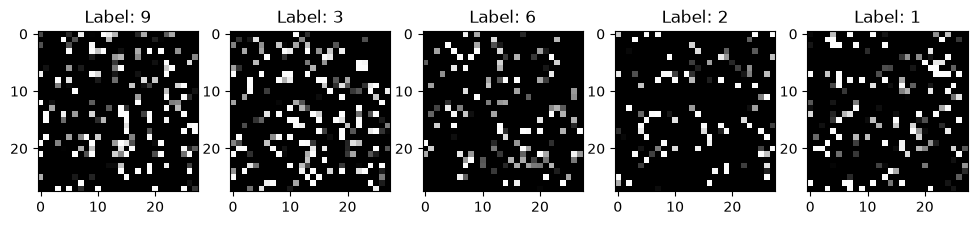

In [51]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    img = train["data"][i].reshape(28, 28)
    axes[i].imshow(img, cmap="gray")

    axes[i].set_title(f"Label: {train["labels"][i]}")

### Forward Pass

In [52]:
def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = z - np.max(z, axis=-1, keepdims=True)
    exp = np.exp(z)
    expsum = np.sum(exp, axis=-1, keepdims=True)
    return exp / expsum

def forward(X, params):
    """
    Parameters:
        X - inputs (m, 784)
        params - dict with keys 'W1', 'b1', 'W2', 'b2'

    Returns:
        y_hat - predicted probability distribution (m, 10)
        cache: dict containing all intermediate values needed by backprop
    """

    # Layer 1 (hidden)
    z1 = X @ params['W1'] + params['b1'] # (m, 784) @ (784, 100) + (100,) = (m, 100)
    a1 = relu(z1) # (m, 100)

    # Layer 2
    z2 = a1 @ params['W2'] + params['b2'] # (m, 100) @ (100, 10) + (10, ) = (m, 10)
    y_hat = softmax(z2) # (m, 10)

    cache = {'X': X, 'z1': z1, 'a1': a1, 'z2': z2, 'y_hat': y_hat}

    return y_hat, cache

### Backpropagation

In [53]:
def backward(y_true, cache, params):
    """
    Parameters:
        y_true: one-hot ground truth labels (m, 10)
        cache:  dict containing ('X', 'z1', 'a1', 'z2', 'y_hat')
        params: dict containing ('W1', 'b1', 'W2', 'b2')

    Returns:
        grads: dict containing ('dW2', 'db2', 'dW1', 'db1')
    """
    m = y_true.shape[0]
    dout2 = cache['y_hat'] - y_true # (m, 10) - (m, 10)
    dout1 = dout2 @ params['W2'].T * (cache['z1'] > 0) # (m, 10) @ (10, 100) * (m, 100)

    dW2 = 1/m * cache['a1'].T @ dout2 # (100, m) @ (m, 10)
    db2 = 1/m * np.sum(dout2, axis=0)

    dW1 = 1/m * cache['X'].T @ dout1 # (m, 784) @ ()
    db1 = 1/m * np.sum(dout1, axis=0)

    grads = {'dW2': dW2, 'db2': db2, 'dW1': dW1, 'db1': db1}
    return grads

### Data Split

In [54]:
X_train, X_val, y_train, y_val = train_test_split(
    train["data"], train["labels"], test_size=0.1, random_state=42, shuffle=True
)

# Pixel scaling
X_train = X_train / 255
X_val = X_val / 255

def one_hot(y, num_classes=10):
    mat = np.eye(num_classes)[np.array(y).reshape(-1)]
    return mat

print(f'Train shape: {X_train.shape}, Val shape: {X_val.shape}')

Train shape: (54000, 784), Val shape: (6000, 784)


In [55]:
# Weights initialization (He Init)
def init_params():
    params = {
        'W1': np.random.randn(784, 100) * np.sqrt(2 / 784),
        'b1': np.zeros(100),
        'W2': np.random.randn(100, 10) * np.sqrt(2 / 100),
        'b2': np.zeros(10)
    }

    return params

In [56]:
# quick test
params = init_params()
y_hat, cache = forward(X_train[:4], params)
grads = backward(one_hot(y_train[:4]), cache, params)
print('Y_hat shape:', y_hat.shape)
print('dW1 shape:', grads['dW1'].shape)

Y_hat shape: (4, 10)
dW1 shape: (784, 100)


In [57]:
def ce_loss(y_true, y_hat, params):
    m = y_true.shape[0]
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)
    ce_loss = - np.sum(y_true * np.log(y_hat)) / m

    return ce_loss

### Training Loop

In [58]:
epochs = 30
batch_size = 64
lr = 0.15
l2 = 3e-4
m = X_train.shape[0]
params = init_params()
v = {k: np.zeros_like(params[k]) for k in params}

train_losses = []
val_losses = []
val_accs = []

best_val_acc = 0.0
best_params = None

for epoch in range(epochs):
    indices = np.random.permutation(m)
    X_train = X_train[indices]
    y_train = y_train[indices]

    for i in range(0, m, batch_size):
        X_batch = X_train[i : i + batch_size]
        y_batch = y_train[i : i + batch_size]
        y_batch = one_hot(y_batch)

        y_hat, cache = forward(X_batch, params)
        grads = backward(y_batch, cache, params)

        for k in params:
            grad = grads['d' + k]
            if k.startswith('W'):
                grad += l2 * params[k] # L2 weight decay

            v[k] = 0.9 * v[k] + (1 - 0.9) * grad # Momentum
            params[k] -= lr * v[k] 

    if (epoch + 1) in [15, 25]:
        lr *= 0.5
        print(f"Lr now: {lr}")

    val_hat, _ = forward(X_val, params)
    val_loss = ce_loss(one_hot(y_val), val_hat, params)
    val_acc = np.mean(np.argmax(val_hat, axis=1) == y_val)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_params = {k: params[k].copy() for k in params}

    train_hat, _ = forward(X_train, params)
    train_loss = ce_loss(one_hot(y_train), train_hat, params)

    val_losses.append(val_loss)
    val_accs.append(val_acc)
    train_losses.append(train_loss)

    print(f"Epoch {epoch + 1}/{epochs} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f} - Val Acc: {val_acc * 100:.2f}%")
print(best_val_acc)

Epoch 1/30 - Train Loss: 0.2126 - Val Loss: 0.2186 - Val Acc: 93.88%
Epoch 2/30 - Train Loss: 0.1505 - Val Loss: 0.1629 - Val Acc: 95.48%
Epoch 3/30 - Train Loss: 0.1156 - Val Loss: 0.1329 - Val Acc: 96.42%
Epoch 4/30 - Train Loss: 0.0983 - Val Loss: 0.1181 - Val Acc: 96.83%
Epoch 5/30 - Train Loss: 0.0892 - Val Loss: 0.1126 - Val Acc: 96.82%
Epoch 6/30 - Train Loss: 0.0727 - Val Loss: 0.0976 - Val Acc: 97.25%
Epoch 7/30 - Train Loss: 0.0700 - Val Loss: 0.0987 - Val Acc: 97.25%
Epoch 8/30 - Train Loss: 0.0643 - Val Loss: 0.0939 - Val Acc: 97.22%
Epoch 9/30 - Train Loss: 0.0551 - Val Loss: 0.0859 - Val Acc: 97.55%
Epoch 10/30 - Train Loss: 0.0509 - Val Loss: 0.0837 - Val Acc: 97.60%
Epoch 11/30 - Train Loss: 0.0475 - Val Loss: 0.0815 - Val Acc: 97.67%
Epoch 12/30 - Train Loss: 0.0474 - Val Loss: 0.0788 - Val Acc: 97.65%
Epoch 13/30 - Train Loss: 0.0427 - Val Loss: 0.0774 - Val Acc: 97.83%
Epoch 14/30 - Train Loss: 0.0416 - Val Loss: 0.0780 - Val Acc: 97.65%
Lr now: 0.075
Epoch 15/30 - T

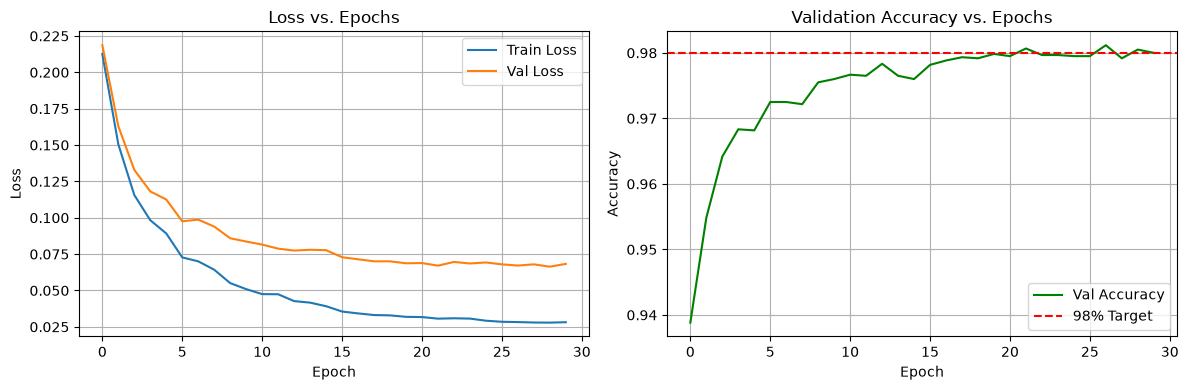

In [59]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses, label="Val Loss")
ax1.set_title("Loss vs. Epochs")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(val_accs, label="Val Accuracy", color="green")
ax2.axhline(0.98, color="red", linestyle="--", label="98% Target")
ax2.set_title("Validation Accuracy vs. Epochs")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Submission

In [60]:
X_test = test['data'] / 255.0

test_hat, _ = forward(X_test, params)
test_preds = np.argmax(test_hat, axis=1)

In [61]:
import pandas as pd

sub = pd.DataFrame({
    'ID': np.arange(len(test_preds)),
    'target': test_preds
})
sub.to_csv('submission.csv', index=False)
print(sub.head())

   ID  target
0   0       8
1   1       7
2   2       8
3   3       2
4   4       9
